In [1]:
import numpy as np
import pandas as pd
import nasdaqdatalink
import seaborn as sns
from matplotlib import pyplot as plt

sns.set_theme(
    context="talk",
    style="whitegrid",
    palette="deep",
    color_codes=True,
    rc={"figure.dpi": 150},
)

In [2]:
nasdaqdatalink.read_key(r"key\secret.txt")

df = nasdaqdatalink.get_table(
    "WIKI/PRICES",
    ticker="AAPL",
    date={"gte": "1996-01-01", "lte": "2026-10-27"},
    paginate=True,
)
df = df.sort_values("date").reset_index(drop=True)
df["date"] = pd.to_datetime(df["date"])

df["simple_return"] = df["adj_close"].pct_change()
df["log_return"] = np.log(df["adj_close"] / df["adj_close"].shift(1))
df[["date", "adj_close", "simple_return", "log_return"]].head()

,date,adj_close,simple_return,log_return
0,1996-01-02,1.032288,NaN,NaN
1,1996-01-03,1.032288,0.000000,0.000000
2,1996-01-04,1.013975,-0.017740,-0.017900
3,1996-01-05,1.100401,0.085234,0.081796
4,1996-01-08,1.112609,0.011095,0.011034


In [3]:
df_cpi = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL")
df_cpi.reset_index(drop=True).head()

,observation_date,CPIAUCSL
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95


In [4]:
monthly = df.set_index("date")["adj_close"].resample("MS").last().to_frame("adj_close")

cpi = df_cpi.rename(columns={"observation_date": "date", "CPIAUCSL": "cpi"})
cpi["date"] = pd.to_datetime(cpi["date"])
cpi = cpi.set_index("date")

data = monthly.join(cpi, how="inner").reset_index()
data = data.iloc[:-1]  # March 2018 partial month bad
data.head()

,date,adj_close,cpi
0,1996-01-01,0.887389,154.7
1,1996-02-01,0.883533,155.0
2,1996-03-01,0.789076,155.5
3,1996-04-01,0.782971,156.1
4,1996-05-01,0.839196,156.4


In [5]:
data = data.copy()
data["simple_return"] = data["adj_close"].pct_change()
data["log_return"] = np.log(data["adj_close"] / data["adj_close"].shift(1))
data["inflation"] = data["cpi"].pct_change()
data["real_return"] = (1 + data["simple_return"]) / (1 + data["inflation"]) - 1
data.head()

,date,adj_close,cpi,simple_return,log_return,inflation,real_return
0,1996-01-01,0.887389,154.7,NaN,NaN,NaN,NaN
1,1996-02-01,0.883533,155.0,-0.004345,-0.004354,0.001939,-0.006272
2,1996-03-01,0.789076,155.5,-0.106909,-0.113067,0.003226,-0.109781
3,1996-04-01,0.782971,156.1,-0.007736,-0.007766,0.003859,-0.011550
4,1996-05-01,0.839196,156.4,0.071810,0.069348,0.001922,0.069754


In [6]:
px_w = df.set_index("date")["adj_close"]
log_ret_w = df.set_index("date")["log_return"]  # ✅ daily

freq_returns_w = {
    f: px_w.resample(f).last().pct_change().dropna() for f in ["W", "MS", "QS", "YS"]
}

# Additivity check: daily log return jog = monthly log return
monthly_log_w = log_ret_w.resample("MS").sum()
check_w = np.log(px_w.resample("MS").last()).diff()
print(
    "Log return additivity ok:",
    np.allclose(monthly_log_w.iloc[1:], check_w.iloc[1:], atol=1e-6),
)

summary_w = pd.DataFrame(
    {
        "mean": {f: r.mean() for f, r in freq_returns_w.items()},
        "std": {f: r.std() for f, r in freq_returns_w.items()},
        "count": {f: len(r) for f, r in freq_returns_w.items()},
    }
)
summary_w

Log return additivity ok: True


,mean,std,count
W,0.006136,0.059130,1160
MS,0.028139,0.125505,266
QS,0.092916,0.256767,88
YS,0.499725,0.794101,22


In [7]:
# Monthly RV: sqrt(sum r^2) * sqrt(12)
rv_monthly_w = log_ret_w.pow(2).resample("MS").sum().pow(0.5) * np.sqrt(12)
rv_monthly_w = rv_monthly_w.iloc[:-1]  # March 2018 partial month bad

# Rolling 21-day RV: std * sqrt(252)
rv_21d_w = log_ret_w.rolling(21).std() * np.sqrt(252)

rv_monthly_w.tail()

date
2017-10-01    0.198087
2017-11-01    0.183854
2017-12-01    0.144173
2018-01-01    0.157473
2018-02-01    0.326442
Freq: MS, Name: log_return, dtype: float64

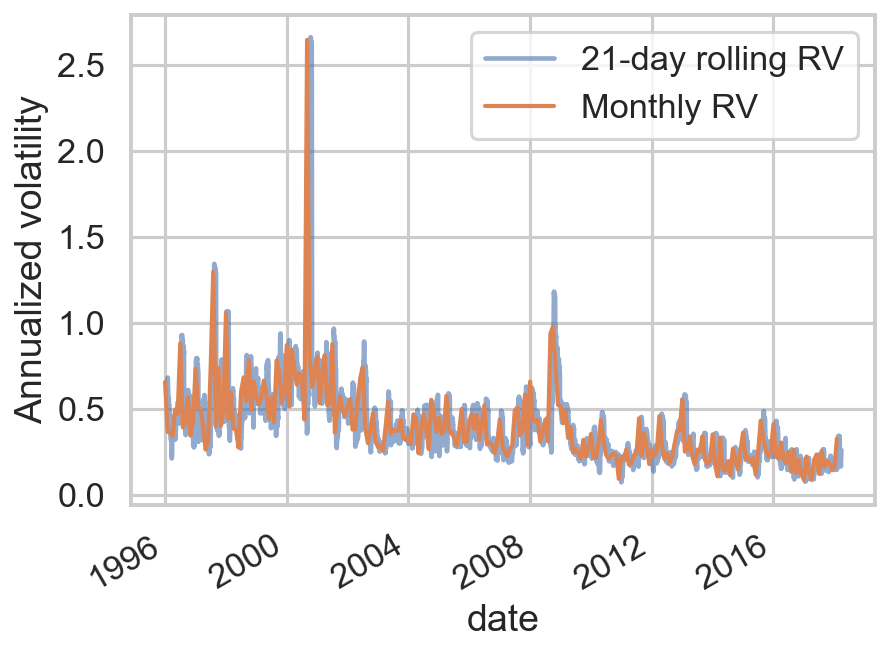

In [8]:
fig, ax = plt.subplots()
rv_21d_w.plot(ax=ax, label="21-day rolling RV", alpha=0.6)
rv_monthly_w.plot(ax=ax, label="Monthly RV", linewidth=2)
ax.set_ylabel("Annualized volatility")
ax.legend()
plt.show()